# Random Forest Machine Learning Project
## Diabetes Prediction Using the Pima Indians Diabetes Dataset

**Problem type:** Binary Classification  
**Algorithm:** Random Forest Classifier  
**Dataset:** Pima Indians Diabetes Database (Kaggle)  
**Kaggle source:** https://www.kaggle.com/datasets/uciml/pima-indians-diabetes-database

### Objective
Build, tune, evaluate, and interpret a Random Forest model that predicts the binary `Outcome` variable from eight diagnostic measurements. This notebook follows the complete required workflow: loading data, exploration, preprocessing, train-test split, Random Forest training, prediction, evaluation, feature importance, cross-validation, hyperparameter tuning, and model saving.

> **Educational use only:** This project demonstrates machine-learning workflow and is not a clinical diagnostic tool.

In [1]:
# 1. Import required libraries
from pathlib import Path
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib

from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix, ConfusionMatrixDisplay,
    RocCurveDisplay, classification_report
)

RANDOM_STATE = 42
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name.upper() == 'SUBMIT' else Path.cwd()
OUTPUT_DIR = PROJECT_ROOT / 'SUPPORT'
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
pd.set_option('display.max_columns', None)
print('Libraries imported successfully.')

Libraries imported successfully.


In [2]:
# 2. Load the dataset
# The CSV is provided in the same submission folder as this notebook.
data_candidates = [
    Path('diabetes.csv'),
    Path.cwd() / 'diabetes.csv',
    Path.cwd() / 'SUBMIT' / 'diabetes.csv',
]
DATA_PATH = next((p for p in data_candidates if p.exists()), None)
if DATA_PATH is None:
    raise FileNotFoundError('diabetes.csv was not found. Keep diabetes.csv in the same folder as this notebook.')

df = pd.read_csv(DATA_PATH)
print(f'Dataset loaded from: {DATA_PATH.resolve()}')
print(f'Shape: {df.shape[0]} rows x {df.shape[1]} columns')
df.head()

Dataset loaded from: /mnt/data/random_forest_diabetes_project/SUBMIT/diabetes.csv
Shape: 768 rows x 9 columns


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


In [3]:
# 3. Basic data exploration
print('Column names:')
print(list(df.columns))

print('\nData types:')
print(df.dtypes)

print('\nMissing values reported by pandas before cleaning:')
print(df.isna().sum())

print('\nTarget distribution:')
print(df['Outcome'].value_counts().rename(index={0: 'No diabetes (0)', 1: 'Diabetes (1)'}))

print('\nStatistical summary:')
display(df.describe().T)

Column names:
['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI', 'DiabetesPedigreeFunction', 'Age', 'Outcome']

Data types:
Pregnancies                   int64
Glucose                       int64
BloodPressure                 int64
SkinThickness                 int64
Insulin                       int64
BMI                         float64
DiabetesPedigreeFunction    float64
Age                           int64
Outcome                       int64
dtype: object

Missing values reported by pandas before cleaning:
Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Outcome                     0
dtype: int64

Target distribution:
Outcome
No diabetes (0)    500
Diabetes (1)       268
Name: count, dtype: int64

Statistical summary:


,count,mean,std,min,25%,50%,75%,max
Pregnancies,768.0,3.845052,3.369578,0.000,1.00000,3.0000,6.00000,17.00
Glucose,768.0,120.894531,31.972618,0.000,99.00000,117.0000,140.25000,199.00
BloodPressure,768.0,69.105469,19.355807,0.000,62.00000,72.0000,80.00000,122.00
SkinThickness,768.0,20.536458,15.952218,0.000,0.00000,23.0000,32.00000,99.00
Insulin,768.0,79.799479,115.244002,0.000,0.00000,30.5000,127.25000,846.00
BMI,768.0,31.992578,7.884160,0.000,27.30000,32.0000,36.60000,67.10
DiabetesPedigreeFunction,768.0,0.471876,0.331329,0.078,0.24375,0.3725,0.62625,2.42
Age,768.0,33.240885,11.760232,21.000,24.00000,29.0000,41.00000,81.00
Outcome,768.0,0.348958,0.476951,0.000,0.00000,0.0000,1.00000,1.00


In [4]:
# 4. Identify and handle missing values
# In this dataset, zero is physiologically invalid for these measurements and is treated as missing.
zero_as_missing = ['Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI']

print('Zero counts before replacement:')
print((df[zero_as_missing] == 0).sum())

# Replace invalid zeros with NaN. Median imputation will be performed inside the ML pipeline
# so that preprocessing is learned only from the training data (avoids data leakage).
df[zero_as_missing] = df[zero_as_missing].replace(0, np.nan)

print('\nMissing values after converting invalid zeros to NaN:')
print(df.isna().sum())

Zero counts before replacement:
Glucose            5
BloodPressure     35
SkinThickness    227
Insulin          374
BMI               11
dtype: int64

Missing values after converting invalid zeros to NaN:
Pregnancies                   0
Glucose                       5
BloodPressure                35
SkinThickness               227
Insulin                     374
BMI                          11
DiabetesPedigreeFunction      0
Age                           0
Outcome                       0
dtype: int64


### Categorical Variable Encoding
All predictor columns in this dataset are numeric, so **categorical encoding is not required**. The target `Outcome` is already binary encoded as `0` and `1`.

In [5]:
# 5. Split features (X) and target (y)
X = df.drop(columns='Outcome')
y = df['Outcome']

print('Feature matrix shape:', X.shape)
print('Target shape:', y.shape)
print('Features:', list(X.columns))

Feature matrix shape: (768, 8)
Target shape: (768,)
Features: ['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI', 'DiabetesPedigreeFunction', 'Age']


In [6]:
# 6. Train-Test Split
# Stratification preserves the class ratio in both train and test sets.
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y
)

print('Training rows:', len(X_train))
print('Testing rows :', len(X_test))
print('Training target ratio:')
print(y_train.value_counts(normalize=True).sort_index())
print('Testing target ratio:')
print(y_test.value_counts(normalize=True).sort_index())

Training rows: 614
Testing rows : 154
Training target ratio:
Outcome
0    0.651466
1    0.348534
Name: proportion, dtype: float64
Testing target ratio:
Outcome
0    0.649351
1    0.350649
Name: proportion, dtype: float64


In [7]:
# 7. Build the preprocessing + Random Forest pipeline
# Median imputation handles missing measurement values inside the pipeline.
model_pipeline = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('rf', RandomForestClassifier(
        random_state=RANDOM_STATE,
        n_jobs=1,
        max_features='sqrt',
        min_samples_split=2
    ))
])

print(model_pipeline)

Pipeline(steps=[('imputer', SimpleImputer(strategy='median')),
                ('rf', RandomForestClassifier(n_jobs=1, random_state=42))])


In [8]:
# 8. Bonus: Hyperparameter tuning with 5-fold Stratified Cross-Validation
# ROC-AUC is used as the tuning score because it evaluates ranking performance across thresholds.
param_grid = {
    'rf__n_estimators': [300, 500],
    'rf__max_depth': [8, 10],
    'rf__min_samples_leaf': [1, 2],
}

cv_strategy = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

grid_search = GridSearchCV(
    estimator=model_pipeline,
    param_grid=param_grid,
    scoring='roc_auc',
    cv=cv_strategy,
    n_jobs=1,
    refit=True,
    return_train_score=False
)

grid_search.fit(X_train, y_train)
best_model = grid_search.best_estimator_

print('Best hyperparameters:')
print(grid_search.best_params_)
print(f'Best mean CV ROC-AUC: {grid_search.best_score_:.4f}')

Best hyperparameters:
{'rf__max_depth': 8, 'rf__min_samples_leaf': 2, 'rf__n_estimators': 300}
Best mean CV ROC-AUC: 0.8304


In [9]:
# 9. Make predictions
y_pred = best_model.predict(X_test)
y_prob = best_model.predict_proba(X_test)[:, 1]

print('Predictions generated successfully.')

Predictions generated successfully.


In [10]:
# 10. Evaluate the model using at least 4 classification metrics
metrics = {
    'Accuracy': accuracy_score(y_test, y_pred),
    'Precision': precision_score(y_test, y_pred, zero_division=0),
    'Recall': recall_score(y_test, y_pred, zero_division=0),
    'F1-Score': f1_score(y_test, y_pred, zero_division=0),
    'ROC-AUC': roc_auc_score(y_test, y_prob),
}
metrics_df = pd.DataFrame({
    'Metric': list(metrics.keys()),
    'Score': list(metrics.values()),
    'Percentage': [f'{v*100:.2f}%' for v in metrics.values()]
})

display(metrics_df)

print('Classification Report:')
print(classification_report(y_test, y_pred, target_names=['No Diabetes', 'Diabetes'], zero_division=0))

,Metric,Score,Percentage
0,Accuracy,0.753247,75.32%
1,Precision,0.690476,69.05%
2,Recall,0.537037,53.70%
3,F1-Score,0.604167,60.42%
4,ROC-AUC,0.810370,81.04%


Classification Report:
              precision    recall  f1-score   support

 No Diabetes       0.78      0.87      0.82       100
    Diabetes       0.69      0.54      0.60        54

    accuracy                           0.75       154
   macro avg       0.73      0.70      0.71       154
weighted avg       0.75      0.75      0.74       154



Confusion Matrix:
[[87 13]
 [25 29]]


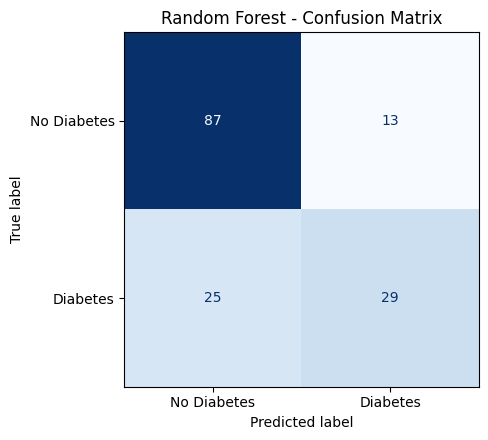

In [11]:
# 11. Confusion Matrix
cm = confusion_matrix(y_test, y_pred)
print('Confusion Matrix:')
print(cm)

fig, ax = plt.subplots(figsize=(5.5, 4.5))
ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['No Diabetes', 'Diabetes']).plot(
    ax=ax, cmap='Blues', values_format='d', colorbar=False
)
ax.set_title('Random Forest - Confusion Matrix')
fig.tight_layout()
fig.savefig(OUTPUT_DIR / 'confusion_matrix.png', dpi=200, bbox_inches='tight')
plt.show()

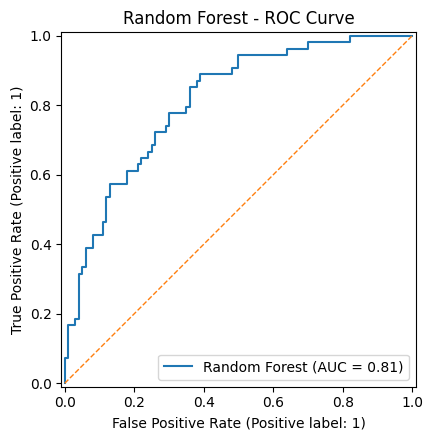

In [12]:
# 12. ROC Curve
fig, ax = plt.subplots(figsize=(5.5, 4.5))
RocCurveDisplay.from_predictions(y_test, y_prob, ax=ax, name='Random Forest')
ax.plot([0, 1], [0, 1], linestyle='--', linewidth=1)
ax.set_title('Random Forest - ROC Curve')
fig.tight_layout()
fig.savefig(OUTPUT_DIR / 'roc_curve.png', dpi=200, bbox_inches='tight')
plt.show()

,Feature,Importance
0,Glucose,0.317744
1,BMI,0.165670
2,Age,0.123670
3,DiabetesPedigreeFunction,0.102713
4,Insulin,0.093102
5,Pregnancies,0.069069
6,BloodPressure,0.064615
7,SkinThickness,0.063418


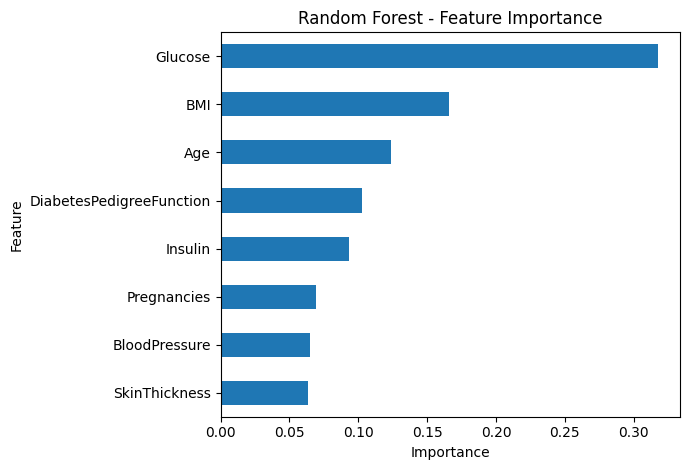

Most important feature: Glucose


In [13]:
# 13. Explain and visualize feature importance
rf_model = best_model.named_steps['rf']
feature_importance = pd.Series(
    rf_model.feature_importances_,
    index=X.columns,
    name='Importance'
).sort_values(ascending=False)

feature_importance_df = feature_importance.reset_index().rename(columns={'index': 'Feature'})
display(feature_importance_df)

fig, ax = plt.subplots(figsize=(7, 4.8))
feature_importance.sort_values().plot(kind='barh', ax=ax)
ax.set_title('Random Forest - Feature Importance')
ax.set_xlabel('Importance')
ax.set_ylabel('Feature')
fig.tight_layout()
fig.savefig(OUTPUT_DIR / 'feature_importance.png', dpi=200, bbox_inches='tight')
plt.show()

print('Most important feature:', feature_importance.index[0])

In [14]:
# 14. Bonus: Cross-validation of the tuned model on the complete dataset
cv_accuracy = cross_val_score(
    best_model, X, y,
    cv=cv_strategy,
    scoring='accuracy',
    n_jobs=1
)
print('5-fold accuracy scores:', np.round(cv_accuracy, 4))
print(f'Mean CV Accuracy: {cv_accuracy.mean():.4f}')
print(f'CV Accuracy Std : {cv_accuracy.std():.4f}')

5-fold accuracy scores: [0.7857 0.7857 0.7922 0.719  0.7386]
Mean CV Accuracy: 0.7642
CV Accuracy Std : 0.0297


In [15]:
# 15. Bonus: Save the trained model and results
MODEL_PATH = OUTPUT_DIR / 'random_forest_diabetes_model.joblib'
METRICS_PATH = OUTPUT_DIR / 'evaluation_metrics.csv'
FEATURE_PATH = OUTPUT_DIR / 'feature_importance.csv'

joblib.dump(best_model, MODEL_PATH)
metrics_df.to_csv(METRICS_PATH, index=False)
feature_importance_df.to_csv(FEATURE_PATH, index=False)

print(f'Model saved to: {MODEL_PATH.resolve()}')
print(f'Metrics saved to: {METRICS_PATH.resolve()}')
print(f'Feature importance saved to: {FEATURE_PATH.resolve()}')

Model saved to: /mnt/data/random_forest_diabetes_project/SUPPORT/random_forest_diabetes_model.joblib
Metrics saved to: /mnt/data/random_forest_diabetes_project/SUPPORT/evaluation_metrics.csv
Feature importance saved to: /mnt/data/random_forest_diabetes_project/SUPPORT/feature_importance.csv


In [16]:
# 16. Final conclusion
print('FINAL PROJECT CONCLUSION')
print('-' * 60)
print(f"The tuned Random Forest achieved {metrics['Accuracy']*100:.2f}% test accuracy, "
      f"{metrics['Precision']*100:.2f}% precision, {metrics['Recall']*100:.2f}% recall, "
      f"{metrics['F1-Score']*100:.2f}% F1-score, and {metrics['ROC-AUC']*100:.2f}% ROC-AUC.")
print(f"The most influential predictor was {feature_importance.index[0]}, followed by {feature_importance.index[1]}.")
print('Invalid zero measurements were treated as missing and median-imputed within the pipeline.')
print('The model was tuned using stratified 5-fold cross-validation and saved with Joblib.')
print('This is an educational ML project and should not be used as a clinical diagnostic system.')

FINAL PROJECT CONCLUSION
------------------------------------------------------------
The tuned Random Forest achieved 75.32% test accuracy, 69.05% precision, 53.70% recall, 60.42% F1-score, and 81.04% ROC-AUC.
The most influential predictor was Glucose, followed by BMI.
Invalid zero measurements were treated as missing and median-imputed within the pipeline.
The model was tuned using stratified 5-fold cross-validation and saved with Joblib.
This is an educational ML project and should not be used as a clinical diagnostic system.
